# Milestone 2: Creating Static Visualizations

This notebook uses `data/weather_14-25_v2.csv` to create graphs and visualizations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
#import data
weather = pd.read_csv("../data/weather_14-25_v2.csv", parse_dates=['DATE'])

In [3]:
weather['SEASON'] = pd.Categorical(weather.SEASON, categories=['Spring', 'Summer', 'Fall', 'Winter'], ordered=True)
weather['STATION'] = pd.Categorical(weather.STATION, categories=['Dublin', 'Toronto', 'San Jose'])
weather['YEAR'] = weather['DATE'].dt.year
weather['MONTH']=weather['DATE'].dt.month
weather.head()

,STATION,DATE,AWND,PRCP,SNOW,TAVG,TMAX,TMIN,SEASON,YEAR,MONTH
0,Dublin,2014-01-01,NaN,3.8,NaN,6.3,10.5,2.7,Winter,2014,1
1,Dublin,2014-01-02,NaN,3.7,NaN,6.8,10.3,4.7,Winter,2014,1
2,Dublin,2014-01-03,NaN,3.1,NaN,6.8,8.3,3.6,Winter,2014,1
3,Dublin,2014-01-04,NaN,0.0,NaN,3.9,7.2,1.2,Winter,2014,1
4,Dublin,2014-01-05,NaN,4.4,NaN,6.9,12.8,1.2,Winter,2014,1


In [4]:
weather.info()

<class 'pandas.DataFrame'>
RangeIndex: 13143 entries, 0 to 13142
Data columns (total 11 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   STATION  13143 non-null  category      
 1   DATE     13143 non-null  datetime64[us]
 2   AWND     4377 non-null   float64       
 3   PRCP     13143 non-null  float64       
 4   SNOW     4396 non-null   float64       
 5   TAVG     8598 non-null   float64       
 6   TMAX     13075 non-null  float64       
 7   TMIN     13072 non-null  float64       
 8   SEASON   13143 non-null  category      
 9   YEAR     13143 non-null  int32         
 10  MONTH    13143 non-null  int32         
dtypes: category(2), datetime64[us](1), float64(6), int32(2)
memory usage: 847.6 KB


In [5]:
# Set colorblind friendly palette
colors = sns.color_palette("colorblind")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")

# Finalized Static Visualizations

The most meaningful graphs are shown below along with design rationale

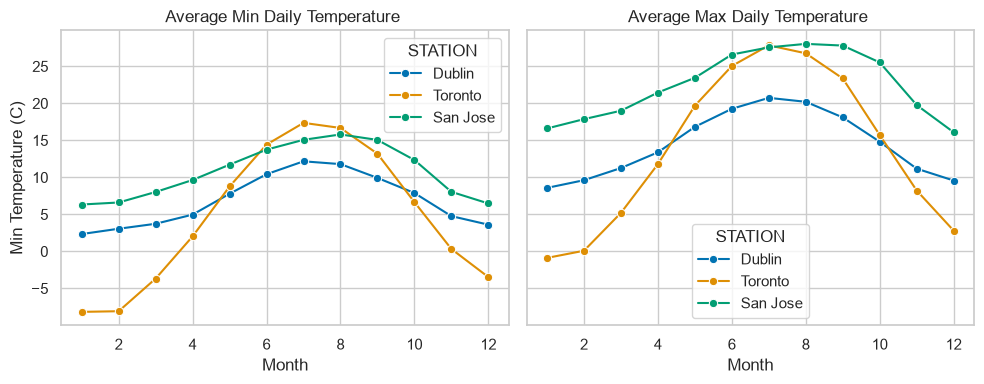

In [6]:
#Lineplot: Min and Max Daily Average Temperatures by Month and Station
mon_min = weather.groupby(["STATION","MONTH"])['TMIN'].mean().reset_index()
mon_max = weather.groupby(['STATION','MONTH'])['TMAX'].mean().reset_index()

fig, axes = plt.subplots(1,2,figsize=(10,4), sharey=True)
sns.lineplot(data=mon_min,x='MONTH',y='TMIN',marker='o',hue="STATION",ax=axes[0])
axes[0].set(title='Average Min Daily Temperature ',xlabel='Month',ylabel='Min Temperature (°C)')

sns.lineplot(data=mon_max,x='MONTH',y='TMAX',marker='o',hue="STATION",ax=axes[1])
axes[1].set(title='Average Max Daily Temperature ',xlabel='Month',ylabel='Max Temperature (°C)')
plt.tight_layout()
plt.show()

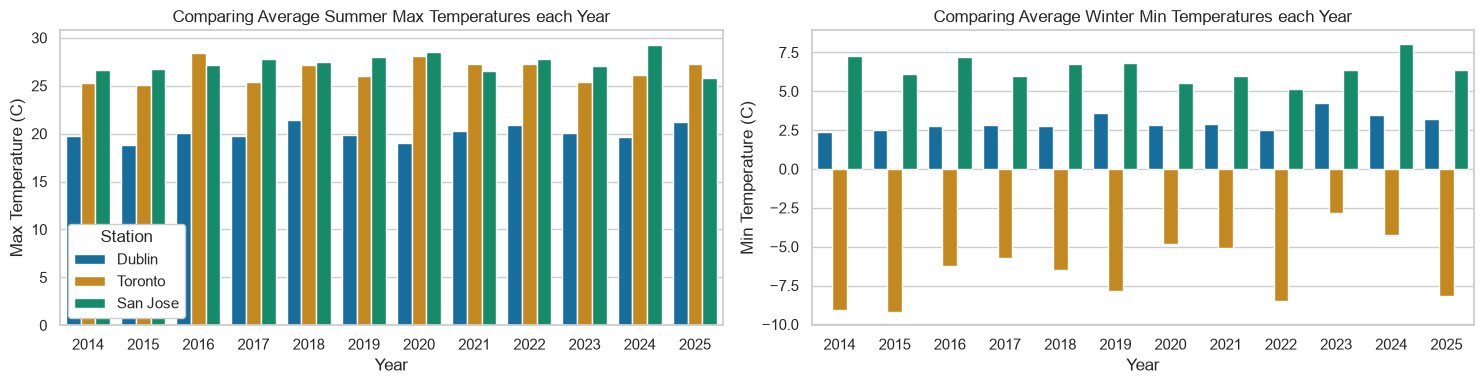

In [54]:
# Grouped Bar Graph: 
# Max average temperature grouped by Station for Summer Season
# Min average temperature grouped by Station for Winter Season

summer_max = (weather[weather['SEASON']=='Summer'].
    groupby(['STATION','YEAR'])['TMAX'].mean().reset_index())

winter_min = (weather[weather['SEASON']=='Winter'].
    groupby(['STATION','YEAR'])['TMIN'].mean().reset_index())

fig, axes = plt.subplots(1,2,figsize=(15,4))
sns.barplot(data=summer_max, x='YEAR',y='TMAX',hue='STATION',ax=axes[0],legend=True)
axes[0].set(title='Comparing Average Summer Max Temperatures each Year',xlabel='Year',ylabel='Max Temperature (C)')

sns.barplot(data=winter_min, x='YEAR',y='TMIN',hue='STATION',ax=axes[1], legend=False)
axes[1].set(title='Comparing Average Winter Min Temperatures each Year',xlabel='Year',ylabel='Min Temperature (C)')

axes[0].legend(title="Station", loc="lower left",framealpha=1)

plt.tight_layout()
plt.show()


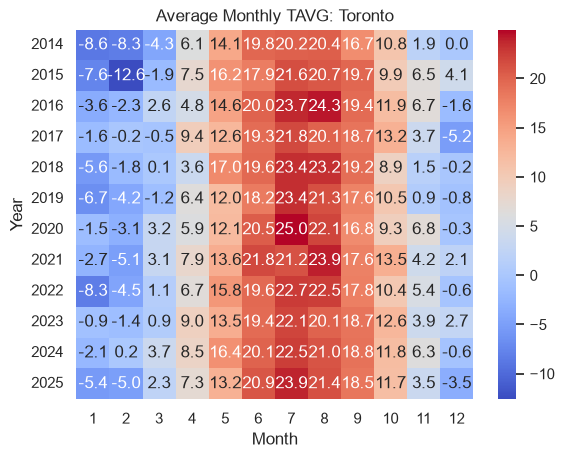

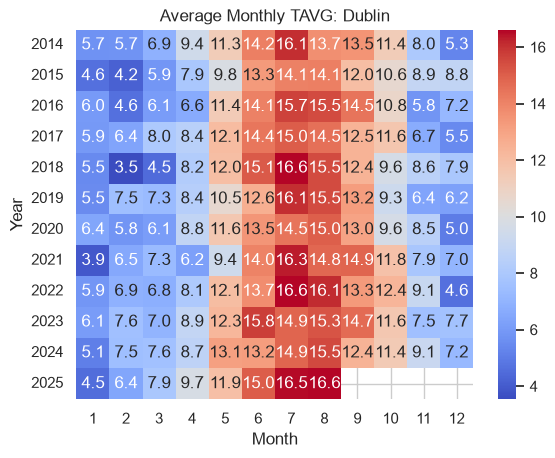

In [8]:
# Compare heatmap of Toronto and Dublin (average temperature)
#Heatmap of monthly averages across years

#Grouping
monthly_avg = weather.groupby(['STATION','YEAR','MONTH'])['TAVG'].mean().reset_index()

#Toronto Heatmap
toronto = monthly_avg[monthly_avg['STATION']=='Toronto']
t_data = toronto.pivot(index='YEAR',columns='MONTH',values='TAVG')
sns.heatmap(
    t_data,
    annot=True,
    fmt='.1f',
    cmap='coolwarm'
)
plt.title('Average Monthly TAVG: Toronto')
plt.xlabel('Month')
plt.ylabel('Year')
plt.show()

#Dublin Heatmap
dublin = monthly_avg[monthly_avg['STATION']=='Dublin']
d_data = dublin.pivot(index='YEAR',columns='MONTH',values='TAVG')
sns.heatmap(
    d_data,
    annot=True,
    fmt='.1f',
    cmap='coolwarm'
)
plt.title('Average Monthly TAVG: Dublin')
plt.xlabel('Month')
plt.ylabel('Year')
plt.show()

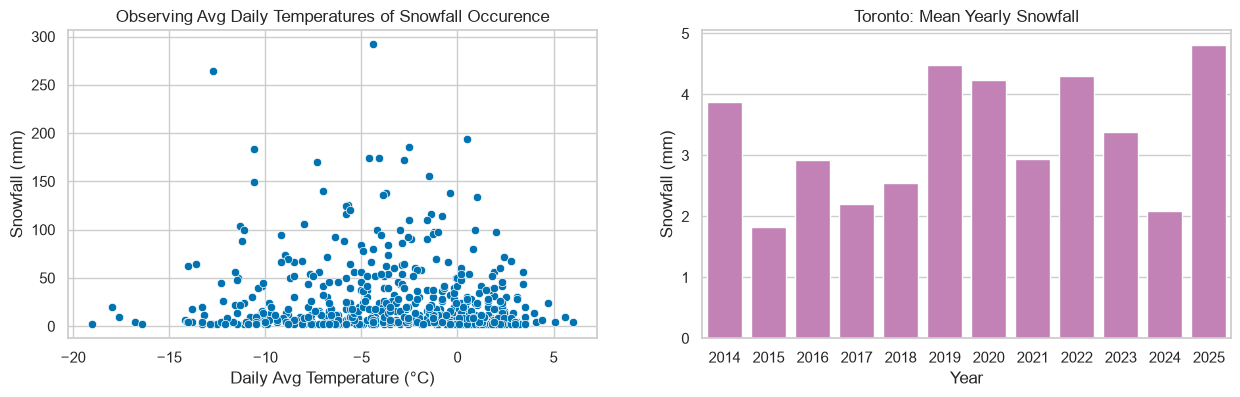

In [46]:
# Analyzing Snow patterns in Toronto
# Scatter plot of snowfall vs min temperature
# Barplot of mean yearly average snowfall in Toronto
snow = (weather[(weather['STATION']=='Toronto') & 
    (weather['SEASON']!='Summer') & (weather['SNOW']>0)])

yearly_snow = weather[weather['STATION']=='Toronto'].groupby('YEAR')['SNOW'].mean().reset_index()

fig, axes = plt.subplots(1,2,figsize=(15,4))
sns.scatterplot(data=snow, x='TAVG',y='SNOW',ax=axes[0])
axes[0].set(title='Observing Avg Daily Temperatures of Snowfall Occurence'
            ,ylabel='Snowfall (mm)',xlabel='Daily Avg Temperature (°C)')

sns.barplot(data=yearly_snow, x='YEAR',y='SNOW',ax=axes[1], color=colors[4])
axes[1].set(title='Toronto: Mean Yearly Snowfall',xlabel='Year',ylabel='Snowfall (mm)')

plt.show()

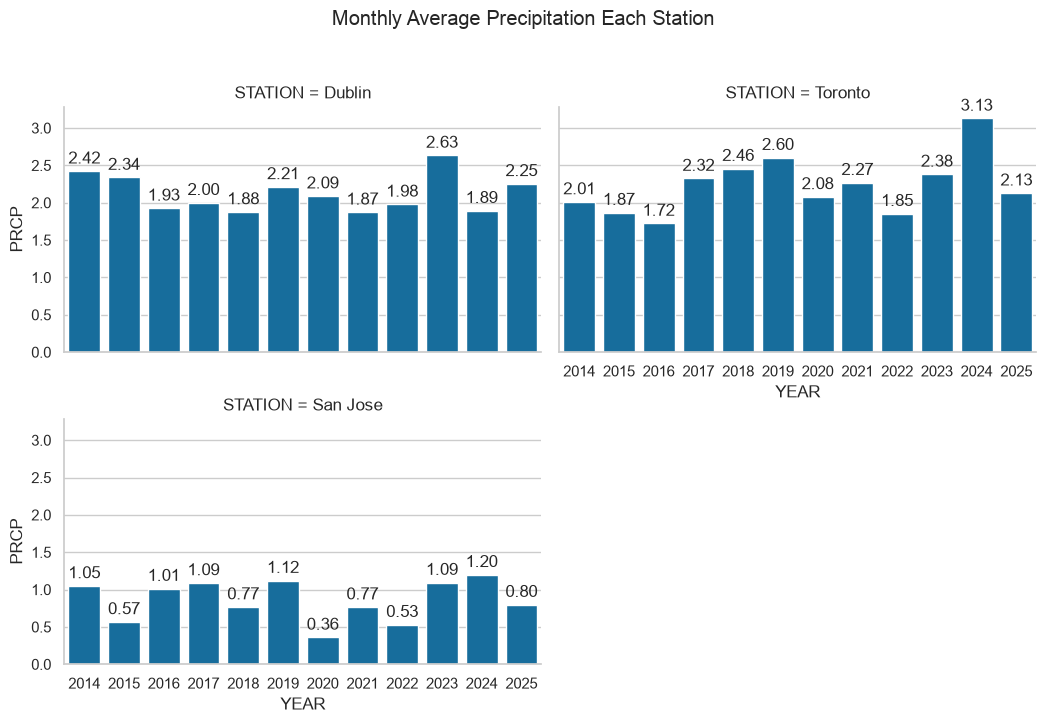

In [53]:
# Faceted Graph of monthly precipitation average of each station

g4 = sns.catplot(data=weather, x='YEAR',y='PRCP',
                 col='STATION',kind='bar',col_wrap=2,
                 height=3.5,aspect=1.5,errorbar=None,)
g4.figure.suptitle("Monthly Average Precipitation Each Station", y=1.03)

#add values on top of the bars
for ax in g4.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

### Story
- story here

### Design Rationale:
Design
- Line Plot was used so that 3 stations on the same graph would be more visible in showing different temperatures
- Grouped barplots was used to emphasize different temperatures for winter and summer months between stations
- 

# Other Exploratory Visualization


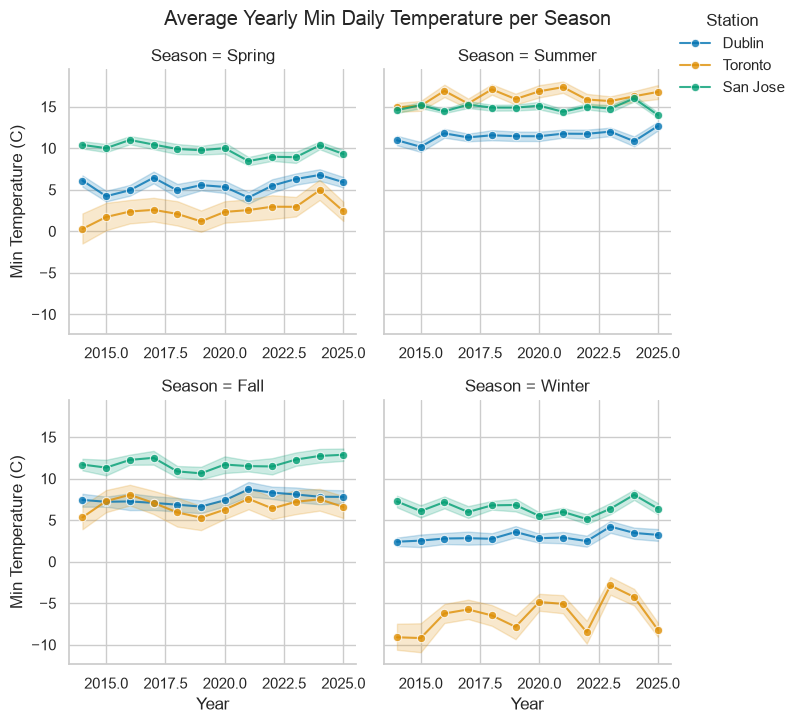

In [11]:
g = sns.FacetGrid(weather, col="SEASON", col_wrap=2,height=3.5,sharex=False, sharey=True)
g.map_dataframe(sns.lineplot,marker='o',x="YEAR", y="TMIN", hue='STATION', alpha=0.8)
g.set_axis_labels("Year", "Min Temperature (°C)")
g.set_titles("Season = {col_name}")
g.figure.suptitle("Average Yearly Min Daily Temperature per Season", y=1.03)
g.add_legend(title='Station',loc='upper right')
plt.show()


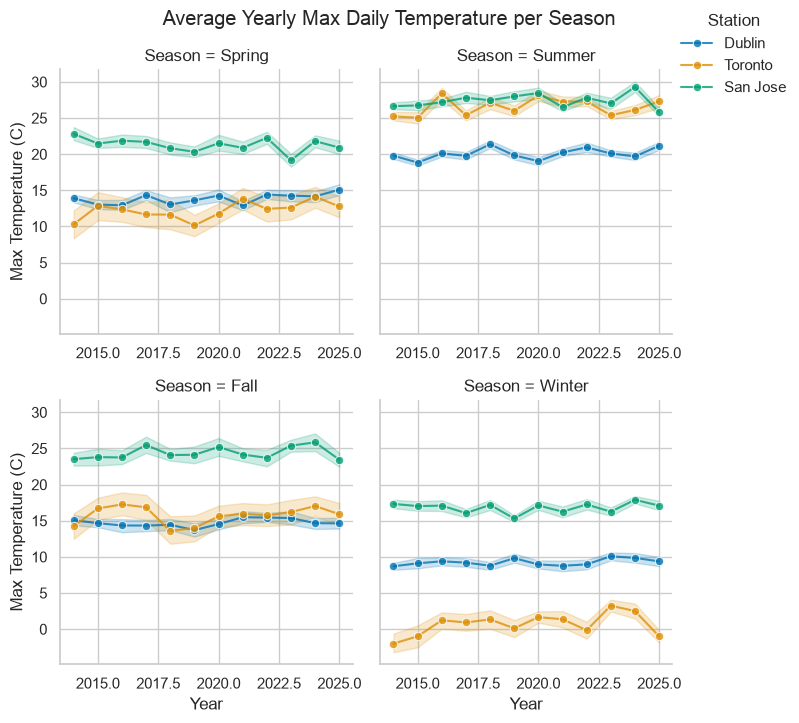

In [12]:
g = sns.FacetGrid(weather, col="SEASON", col_wrap=2,height=3.5,sharex=False, sharey=True)
g.map_dataframe(sns.lineplot,marker='o',x="YEAR", y="TMAX", hue='STATION', alpha=0.8)
g.set_axis_labels("Year", "Max Temperature (°C)")
g.set_titles("Season = {col_name}")
g.figure.suptitle("Average Yearly Max Daily Temperature per Season", y=1.03)
g.add_legend(title='Station',loc='upper right')
plt.show()

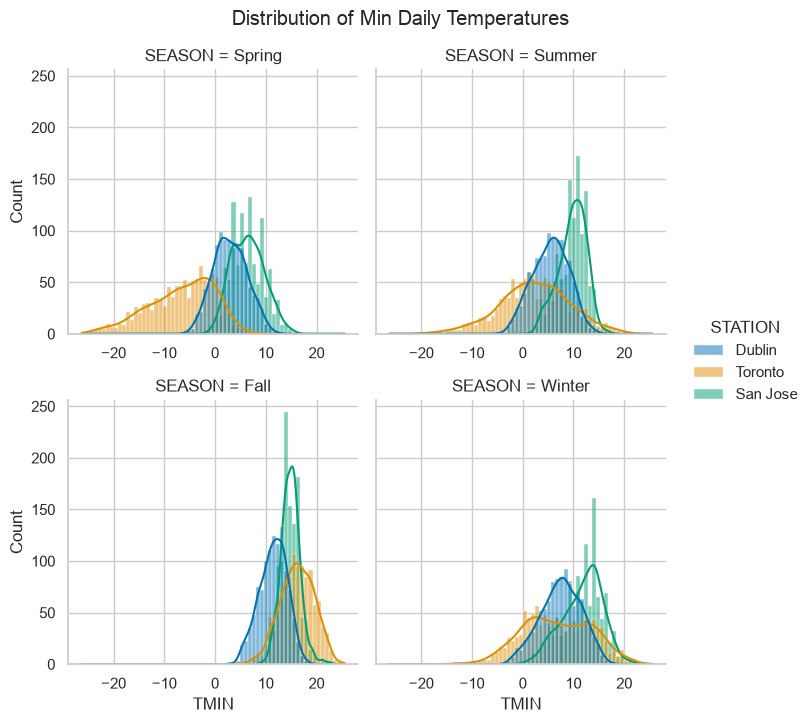

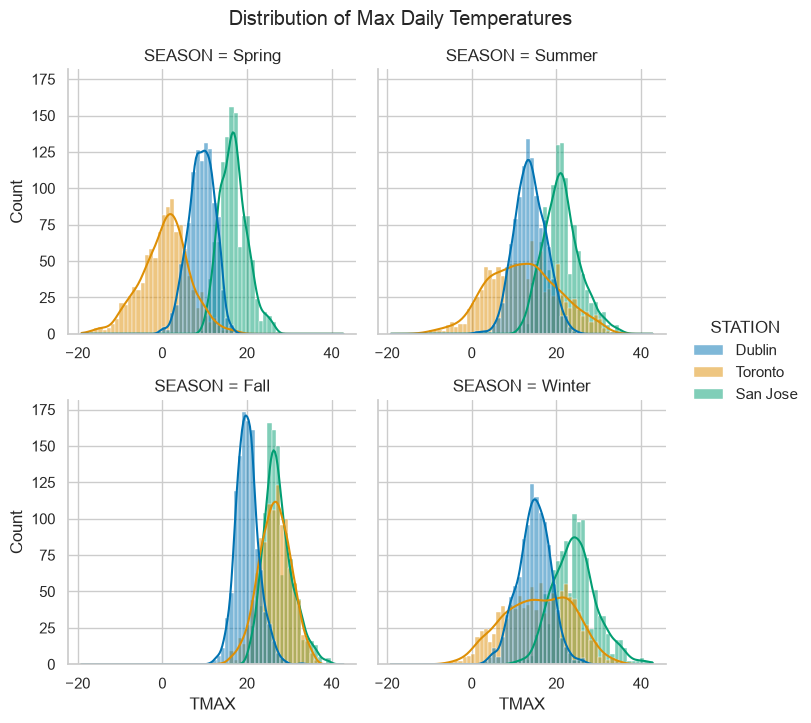

In [13]:
#histogram of weather distribution?? --> Overall for all 3
g2 = sns.displot(data=weather, x="TMIN", col="SEASON",
                 kind="hist", hue='STATION', kde=True, col_wrap=2,height=3.5
                ,facet_kws={"sharex": False, "sharey": True})
g2.figure.suptitle("Distribution of Min Daily Temperatures", y=1.03)

# Max Temperature
g3 = sns.displot(data=weather, x="TMAX", col="SEASON",
                 kind="hist", hue='STATION', kde=True, col_wrap=2,height=3.5
                ,facet_kws={"sharex": False, "sharey": True})
g3.figure.suptitle("Distribution of Max Daily Temperatures", y=1.03)
plt.show()

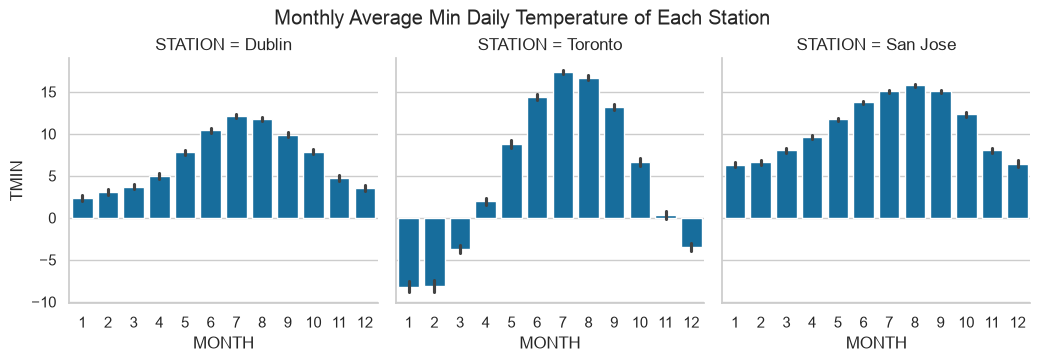

In [14]:
g4 = sns.catplot(data=weather, x='MONTH',y='TMIN'
                ,col='STATION',kind='bar',col_wrap=3,height=3.5)
g4.figure.suptitle("Monthly Average Min Daily Temperature of Each Station", y=1.03)
plt.show()

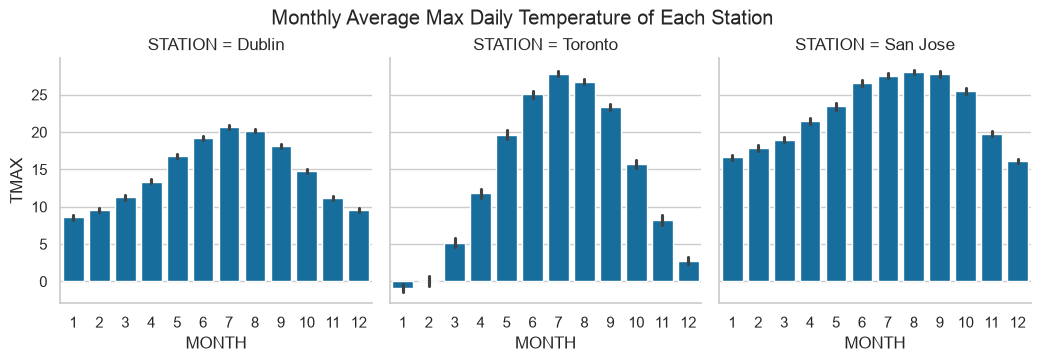

In [15]:
g4 = sns.catplot(data=weather, x='MONTH',y='TMAX'
                ,col='STATION',kind='bar',col_wrap=3,height=3.5)
g4.figure.suptitle("Monthly Average Max Daily Temperature of Each Station", y=1.03)
plt.show()

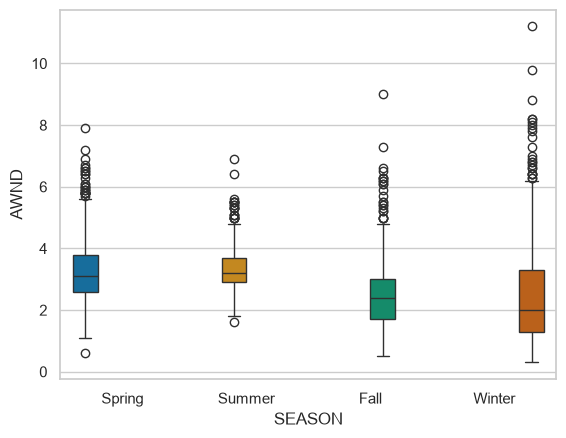

In [16]:
#AWND
sj = weather[(weather['STATION']=='San Jose')]
sns.boxplot(data=sj, x='SEASON',y='AWND',hue='SEASON')
plt.show()

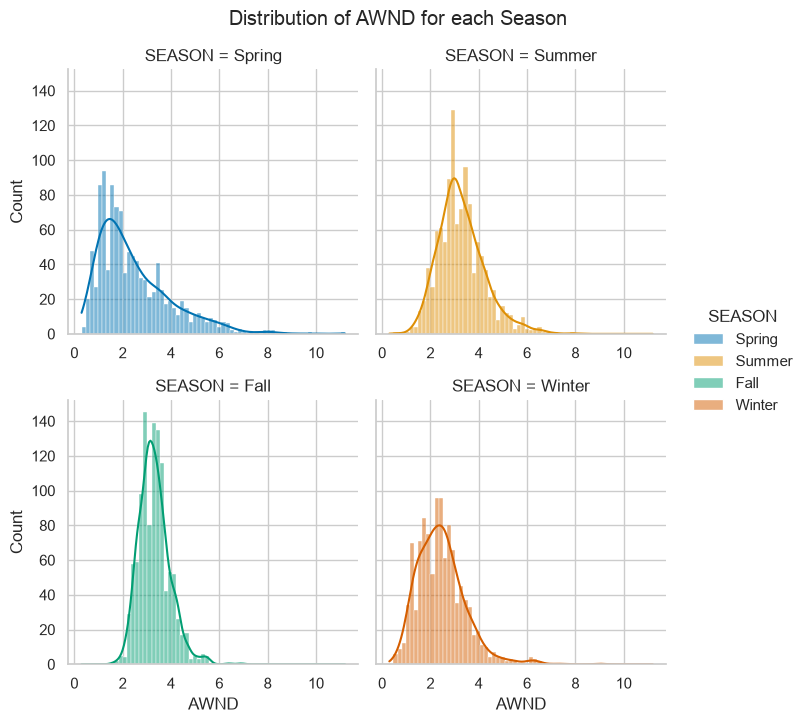

In [17]:

g3 = sns.displot(data=sj, x="AWND", col="SEASON", hue='SEASON',
                 kind="hist", kde=True, col_wrap=2,height=3.5
                ,facet_kws={"sharex": False, "sharey": True})
g3.figure.suptitle("Distribution of AWND for each Season", y=1.03)
plt.show()